# Position decoding: Naive Bayes vs. NB+continuity vs. Transformer

Three decoders that map population spiking activity to allocentric position, all trained on the same `bat_data_loader` train/valid/test split:

1. **`NaiveBayes_Decoder`** (Zhang et al. 1998 — "Bayesian 1-step") — per-session Poisson rate maps fit on training timepoints; argmax of the log-posterior at each timestep, independently.
2. **`NaiveBayes_Continuity_Decoder`** (Zhang et al. 1998 — "Bayesian 2-step") — same rate maps as #1, but adds a Gaussian transition prior `P(x_{t-1} | x_t)` with width `σ_t = c · U(x_t)`, where `U(x)` is the per-bin average instantaneous speed estimated from training data. Decoded greedy-forward per flight.
3. **`Bat_Transformer_Decoder`** — RoPE transformer that inverts `Bat_Transformer`. Per-session `nn.Linear(num_neurons, latent_dim)` readins serve as neuron-specific embeddings, followed by transformer encoder layers and a shared linear head to z-scored 3D position.

All three decoders are evaluated on held-out test data; we report 2D (x, y) and 3D (x, y, z) decoding error in meters per session.

In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd
import torch
from torch import nn
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.decoder import (
    Bat_Transformer_Decoder,
    NaiveBayes_Decoder,
    NaiveBayes_Continuity_Decoder,
    bat_decoder_trainer,
)
from digitalbat.utility.utils import set_random_state

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

## 1. Dataloader

Same configuration as `preprocess-data-v0j-share.ipynb` so the train/valid/test split lines up with the encoder analyses.

In [5]:
session_names = [
    'Dataset_3_14543_240419',
    'Dataset_3_14543_240420',
    'Dataset_3_14543_240421',
    'Dataset_3_29959_240402',
    'Dataset_3_29959_240403',
    'Dataset_3_29959_240404',
    'Dataset_2_14445_231208',
    'Dataset_2_14445_231209',
    'Dataset_1_32622_231009',
    'Dataset_1_32622_231010',
    'Dataset_1_32622_231007',
    'Dataset_2_14611_231208',
    'Dataset_2_14611_231209',
    'Dataset_3_00000_240402',
    'Dataset_3_00000_240403',
    'Dataset_3_00000_240404',
    'Dataset_3_00000_240405',
    'Dataset_3_29959_240405',
]

data_config = dict(
    use_speed_head_dir=False,
    use_IMU_flag=False,
    use_click_flag=False,
    use_LFP_flag=False,
    use_ripple_flag=False,
    only_flight_flag=True,
    no_3d_location=False,
    spike_count_flag=True,
    bin_width=0.10,
    split_flights_for_train='random',
    type_train_num=1,
    type_valid_num=1,
    special_id_count_thresh=3,
    only_use_special_id_4train_flag=False,
    shuffle_flag=True,
    time_shuffle_for_trajecotry_flag=False,
    simulate_place_cell_flag=False,
    split_each_trajectory_flag=True,
    window_size=None,
    stride_train=None,
    stride_test=None,
    batch_size_train=None,
    batch_size_test=None,
    session_names=session_names,
    parent_folder='/mnt/s5/Adam/Angelo/NP_datasets/',
    max_acceleration=50,
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'behavior_dim = {behavior_dim}, sessions = {len(unit_num_dict)}')
unit_num_dict

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
behavior_dim = 3, sessions = 18


{'Dataset_3_14543_240419': 289,
 'Dataset_3_14543_240420': 126,
 'Dataset_3_14543_240421': 100,
 'Dataset_3_29959_240402': 317,
 'Dataset_3_29959_240403': 191,
 'Dataset_3_29959_240404': 190,
 'Dataset_2_14445_231208': 237,
 'Dataset_2_14445_231209': 168,
 'Dataset_1_32622_231009': 95,
 'Dataset_1_32622_231010': 54,
 'Dataset_1_32622_231007': 167,
 'Dataset_2_14611_231208': 236,
 'Dataset_2_14611_231209': 186,
 'Dataset_3_00000_240402': 394,
 'Dataset_3_00000_240403': 207,
 'Dataset_3_00000_240404': 147,
 'Dataset_3_00000_240405': 122,
 'Dataset_3_29959_240405': 143}

## 2. Transformer decoder

Per-session readins → RoPE transformer → linear head to z-scored 3D position. Loss is MSE on z-scored space, masked to valid timesteps. The first 3 channels of `batch.behavior` are the (z-scored) (x, y, z) targets.

We use **Optuna (TPE)** to search dropout, readin dropout, latent_dim, ff_dim, num_layers, and input_transform. Each trial trains up to 1000 epochs with early stopping (patience 30). The final model is then refit with the best params and patience 50.

In [18]:
import optuna

# Fixed (non-searched) hyperparameters
fixed_config = dict(
    input_dim_dict=unit_num_dict,
    output_dim=3,
    num_heads=4,
    final_activation=nn.Identity(),
)

MAX_EPOCHS = 1000
TRIAL_PATIENCE = 30
N_TRIALS = 12


def make_model(params):
    return Bat_Transformer_Decoder(
        latent_dim=params['latent_dim'],
        ff_dim=params['ff_dim'],
        num_layers=params['num_layers'],
        dropout_prob=params['dropout_prob'],
        readin_dropout=params['readin_dropout'],
        input_transform=params['input_transform'],
        **fixed_config,
    )


def objective(trial):
    params = dict(
        latent_dim=trial.suggest_categorical('latent_dim', [32, 64, 128]),
        ff_dim=trial.suggest_categorical('ff_dim', [32, 64, 128]),
        num_layers=trial.suggest_int('num_layers', 1, 3),
        dropout_prob=trial.suggest_float('dropout_prob', 0.0, 0.5),
        readin_dropout=trial.suggest_float('readin_dropout', 0.0, 0.3),
        input_transform=trial.suggest_categorical('input_transform', ['identity', 'sqrt']),
    )
    set_random_state(seed)
    model = make_model(params)
    best_score, _, _ = bat_decoder_trainer(
        model=model,
        dataloaders=dataloaders,
        device=device,
        pos_dims=3,
        n_epochs=MAX_EPOCHS,
        lr=1e-3,
        weight_decay=0.01,
        loss_fn=nn.MSELoss(),
        valid_stat='mean',
        early_stopping_patience=TRIAL_PATIENCE,
        save_model=False,
    )
    return best_score  # higher (less-negative MSE) is better

In [19]:
os.makedirs('./out', exist_ok=True)
study_path = f'./out/bat_decoder_seed_{seed}_optuna.pkl'

if os.path.exists(study_path):
    import pickle
    with open(study_path, 'rb') as f:
        study = pickle.load(f)
    print(f'Loaded existing study with {len(study.trials)} trials')
else:
    sampler = optuna.samplers.TPESampler(seed=seed)
    study = optuna.create_study(direction='maximize', sampler=sampler)

# Top up to N_TRIALS
remaining = max(0, N_TRIALS - len(study.trials))
if remaining > 0:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study.optimize(objective, n_trials=remaining, show_progress_bar=True)
    import pickle
    with open(study_path, 'wb') as f:
        pickle.dump(study, f)

print(f'\nBest score (mean -MSE per dim): {study.best_value:.4f}')
print('Best params:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')
trials_df = study.trials_dataframe()
trials_df.sort_values('value', ascending=False).head(10)

[I 2026-04-29 17:43:05,055] A new study created in memory with name: no-name-d1e16b3b-340e-4a07-8c2f-9c5b79bf3b66


  0%|          | 0/12 [00:00<?, ?it/s]

Decoder training:  30%|██▉       | 295/1000 [00:44<01:46,  6.63it/s]


Early stopping at epoch 296 (no improvement for 30 epochs)


Decoder training:  24%|██▍       | 241/1000 [00:40<02:09,  5.88it/s]


...

Decoder training:   6%|▌         | 61/1000 [00:11<03:00,  5.19it/s]


Early stopping at epoch 62 (no improvement for 30 epochs)


Decoder training:  23%|██▎       | 234/1000 [00:33<01:48,  7.07it/s]

Early stopping at epoch 235 (no improvement for 30 epochs)

Best score (mean -MSE per dim): -0.2779
Best params:
  latent_dim: 64
  ff_dim: 32
  num_layers: 1
  dropout_prob: 0.17278036352152387
  readin_dropout: 0.11903024226920098
  input_transform: identity


,number,value,datetime_start,datetime_complete,duration,params_dropout_prob,params_ff_dim,params_input_transform,params_latent_dim,params_num_layers,params_readin_dropout,state
0,0,-0.277859,2026-04-29 17:43:05.058592,2026-04-29 17:43:49.610404,0 days 00:00:44.551812,0.172780,32,identity,64,1,0.119030,COMPLETE
6,6,-0.295145,2026-04-29 17:46:12.172972,2026-04-29 17:46:31.349322,0 days 00:00:19.176350,0.403696,64,sqrt,128,1,0.119303,COMPLETE
1,1,-0.297162,2026-04-29 17:43:49.610989,2026-04-29 17:44:30.609947,0 days 00:00:40.998958,0.070193,64,sqrt,128,2,0.059430,COMPLETE
11,11,-0.302368,2026-04-29 17:48:39.796176,2026-04-29 17:49:12.913494,0 days 00:00:33.117318,0.231266,64,identity,128,1,0.125088,COMPLETE
4,4,-0.305348,2026-04-29 17:45:10.543789,2026-04-29 17:45:29.938165,0 days 00:00:19.394376,0.339418,32,sqrt,128,1,0.063488,COMPLETE
2,2,-0.313458,2026-04-29 17:44:30.610441,2026-04-29 17:44:49.017870,0 days 00:00:18.407429,0.439071,32,sqrt,128,1,0.029504,COMPLETE
7,7,-0.314160,2026-04-29 17:46:31.349798,2026-04-29 17:47:06.332822,0 days 00:00:34.983024,0.134964,32,sqrt,64,2,0.268766,COMPLETE
8,8,-0.315209,2026-04-29 17:47:06.333286,2026-04-29 17:47:49.856062,0 days 00:00:43.522776,0.118513,32,identity,32,2,0.271014,COMPLETE
9,9,-0.323217,2026-04-29 17:47:49.856546,2026-04-29 17:48:28.029722,0 days 00:00:38.173176,0.007911,128,sqrt,32,2,0.278831,COMPLETE
5,5,-0.355620,2026-04-29 17:45:29.938674,2026-04-29 17:46:12.172499,0 days 00:00:42.233825,0.347200,64,sqrt,64,2,0.124254,COMPLETE


In [20]:
best_params = study.best_params
input_tag = best_params['input_transform']
model_path = f'./out/bat_decoder_seed_{seed}_best_{input_tag}.pth'

set_random_state(seed)
decoder_model = make_model(best_params)
n_params = sum(p.numel() for p in decoder_model.parameters() if p.requires_grad)
print(f'Final model params: {n_params:,}')

if os.path.exists(model_path):
    print(f'Loading existing weights from {model_path}')
    decoder_model.load_state_dict(torch.load(model_path, map_location=device))
    decoder_model = decoder_model.to(device)
    val_scores = None
else:
    best_score, _, val_scores = bat_decoder_trainer(
        model=decoder_model,
        dataloaders=dataloaders,
        device=device,
        pos_dims=3,
        n_epochs=MAX_EPOCHS,
        lr=1e-3,
        weight_decay=0.01,
        loss_fn=nn.MSELoss(),
        valid_stat='mean',
        early_stopping_patience=50,
        save_model=True,
        model_name=model_path,
    )
    print(f'Final best_score (mean -MSE per dim): {best_score:.4f}')

Final model params: 238,051


Decoder training:  32%|███▏      | 315/1000 [00:44<01:36,  7.11it/s]

Early stopping at epoch 316 (no improvement for 50 epochs)
Final best_score (mean -MSE per dim): -0.2779


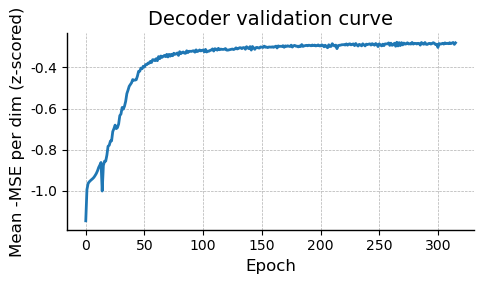

In [21]:
if val_scores is not None:
    plt.figure(figsize=(5, 3))
    plt.plot(val_scores)
    plt.xlabel('Epoch')
    plt.ylabel('Mean -MSE per dim (z-scored)')
    plt.title('Decoder validation curve')
    plt.tight_layout()
    plt.show()

### 2a. Evaluate the transformer decoder on test data

We un-z-score the predictions per session using `meta_info_dict['behavior_mean']` / `behavior_std`, then compute 2D (x, y) error in meters at each valid timestep.

In [ ]:
def parse_bat(session_name):
    """`Dataset_3_14543_240419` → '14543'."""
    return session_name.split('_')[2]


decoder_model.eval()

transformer_records = []
with torch.no_grad():
    for session_name, session_data in dataloaders['test'].items():
        bm = meta_info_dict['behavior_mean'][session_name].squeeze()  # (behavior_dim,)
        bs = meta_info_dict['behavior_std'][session_name].squeeze()
        bat = parse_bat(session_name)
        for batch in session_data:
            X = batch.spike.to(device)
            m = batch.mask.to(device)
            y_true_z = batch.behavior[:, :, :3].numpy()
            y_pred_z = decoder_model(session_name, X, m).cpu().numpy()
            mask_np = batch.mask.numpy().astype(bool)
            B, T = mask_np.shape
            # un-z-score → meters
            y_true = y_true_z * bs[None, None, :3] + bm[None, None, :3]
            y_pred = y_pred_z * bs[None, None, :3] + bm[None, None, :3]
            fpi_np = batch.flight_path_index.numpy()
            fpi_per_t = np.broadcast_to(fpi_np[:, None], (B, T))
            t_idx_per = np.broadcast_to(np.arange(T)[None, :], (B, T))

            y_true_flat = y_true[mask_np]
            y_pred_flat = y_pred[mask_np]
            fpi_flat = fpi_per_t[mask_np].astype(int)
            t_flat = t_idx_per[mask_np].astype(int)
            err_2d = np.sqrt(((y_true_flat[:, :2] - y_pred_flat[:, :2]) ** 2).sum(axis=1))
            err_3d = np.sqrt(((y_true_flat - y_pred_flat) ** 2).sum(axis=1))
            for i in range(len(err_2d)):
                transformer_records.append({
                    'bat': bat,
                    'session': session_name,
                    'flight_id': int(fpi_flat[i]),
                    't_idx': int(t_flat[i]),
                    'x_true': float(y_true_flat[i, 0]),
                    'y_true': float(y_true_flat[i, 1]),
                    'z_true': float(y_true_flat[i, 2]),
                    'x_pred': float(y_pred_flat[i, 0]),
                    'y_pred': float(y_pred_flat[i, 1]),
                    'z_pred': float(y_pred_flat[i, 2]),
                    'err_2d': float(err_2d[i]),
                    'err_3d': float(err_3d[i]),
                })

transformer_df = pd.DataFrame(transformer_records)
transformer_df['decoder'] = 'transformer'
transformer_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')

## 3. Naive Bayes decoder

Per session we fit **two** Naive Bayes decoders independently:
- `nb_2d`: 2D rate maps over (x, y) — used for 2D error.
- `nb_3d`: 3D rate maps over (x, y, z) — used for 3D error.

Fitting them separately is fairer than projecting a 3D decoder to 2D, because 3D occupancy is sparser per voxel and the 2D map marginalizes over z. Bin edges come from `meta_info_dict['r_lim']`. Spikes are raw counts; positions are recovered from the z-scored `batch.behavior` using session-specific mean/std.

We also use **Optuna** to search NB hyperparameters on the validation set: smoothing kernel `sigma` (in bins), grid resolution `n_bins` per axis, `min_occupancy` (threshold for which bins are "in support" before smoothing), and `use_uniform_prior` (uniform prior over support vs. empirical-occupancy prior). The objective is the mean across sessions of each session's median position error in meters. A single set of HPs is picked per ndim — the same way the transformer uses one set across sessions.

In [ ]:
def gather_session_arrays(loader, behavior_mean, behavior_std):
    """Concatenate spikes / positions / flight_id / t_idx over all batches.

    Returns dict with raw (un-z-scored) positions and raw spike counts on
    valid timesteps only. `flight_id` is `batch.flight_path_index` broadcast
    to per-timestep, and `t_idx` is the within-flight time-bin index — both
    needed to draw per-flight trajectory lines.
    """
    spk_list, beh_list, mask_list, fpi_list = [], [], [], []
    for batch in loader:
        spk_list.append(batch.spike.numpy())
        beh_list.append(batch.behavior.numpy())
        mask_list.append(batch.mask.numpy().astype(bool))
        fpi_list.append(batch.flight_path_index.numpy())
    spikes = np.concatenate(spk_list, axis=0)        # (B, T, K)
    behavior = np.concatenate(beh_list, axis=0)      # (B, T, behavior_dim)
    mask = np.concatenate(mask_list, axis=0)         # (B, T)
    fpi = np.concatenate(fpi_list, axis=0)           # (B,)

    bm = np.asarray(behavior_mean).squeeze()
    bs = np.asarray(behavior_std).squeeze()
    pos = behavior[..., :3] * bs[None, None, :3] + bm[None, None, :3]

    B, T, _ = behavior.shape
    fpi_per_t = np.broadcast_to(fpi[:, None], (B, T))
    t_idx_per = np.broadcast_to(np.arange(T)[None, :], (B, T))

    return {
        'spikes': spikes[mask],
        'pos_x': pos[..., 0][mask],
        'pos_y': pos[..., 1][mask],
        'pos_z': pos[..., 2][mask],
        'flight_id': fpi_per_t[mask].astype(int),
        't_idx': t_idx_per[mask].astype(int),
    }

In [ ]:
NB_N_TRIALS = 20

# Pre-gather train + valid arrays per session so each Optuna trial only needs
# to re-fit + re-predict, not re-iterate the dataloader.
session_arrays = {}
for s in dataloaders['test'].keys():
    bm = meta_info_dict['behavior_mean'][s]
    bs = meta_info_dict['behavior_std'][s]
    r_lim = meta_info_dict['r_lim'][s]
    train = gather_session_arrays(dataloaders['train'][s], bm, bs)
    valid = gather_session_arrays(dataloaders['valid'][s], bm, bs)
    if train['spikes'].shape[0] < 100 or valid['spikes'].shape[0] < 10:
        continue
    session_arrays[s] = (train, valid, r_lim)
print(f'NB search using {len(session_arrays)}/{len(dataloaders["test"])} sessions')


def nb_objective(trial, ndim):
    sigma = trial.suggest_float('sigma', 0.5, 4.0)
    n_bins_x = trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50])
    n_bins_y = trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50])
    min_occ = trial.suggest_int('min_occupancy', 1, 10)
    use_uniform = trial.suggest_categorical('use_uniform_prior', [True, False])
    if ndim == 3:
        n_bins_z = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        n_bins = (n_bins_x, n_bins_y, n_bins_z)
    else:
        n_bins = (n_bins_x, n_bins_y)

    cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
    per_session_med_err = []
    for s, (train, valid, r_lim) in session_arrays.items():
        train_pos = np.column_stack([train[c] for c in cols])
        valid_pos = np.column_stack([valid[c] for c in cols])
        try:
            nb = NaiveBayes_Decoder(
                n_bins=n_bins,
                lims=[tuple(r_lim[d]) for d in range(ndim)],
                sigma=sigma,
                dt=data_config['bin_width'],
                min_occupancy=min_occ,
                use_uniform_prior=use_uniform,
            ).fit(train['spikes'], train_pos)
            pos_dec, _ = nb.predict(valid['spikes'])
            err = np.sqrt(((valid_pos - pos_dec) ** 2).sum(axis=1))
            per_session_med_err.append(np.median(err))
        except Exception:
            # bin/lim choice incompatible with this session → mark trial bad
            return -np.inf
    # mean across sessions of per-session median error (each session weighted equally)
    return -float(np.mean(per_session_med_err))


nb_best = {}
for ndim in (2, 3):
    study_path = f'./out/nb_decoder_{ndim}d_seed_{seed}_optuna.pkl'
    if os.path.exists(study_path):
        import pickle
        with open(study_path, 'rb') as f:
            study = pickle.load(f)
        print(f'NB-{ndim}D: loaded existing study with {len(study.trials)} trials')
    else:
        sampler = optuna.samplers.TPESampler(seed=seed)
        study = optuna.create_study(direction='maximize', sampler=sampler)

    remaining = max(0, NB_N_TRIALS - len(study.trials))
    if remaining > 0:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        study.optimize(lambda t, n=ndim: nb_objective(t, n),
                       n_trials=remaining, show_progress_bar=True)
        import pickle
        with open(study_path, 'wb') as f:
            pickle.dump(study, f)

    nb_best[ndim] = study.best_params
    print(f'NB-{ndim}D best valid err (mean of per-session medians): {-study.best_value:.4f} m')
    print(f'  best params: {study.best_params}')

In [ ]:
def make_nb(ndim, r_lim, params):
    """Instantiate a NB decoder from Optuna best_params + per-session r_lim."""
    if ndim == 3:
        n_bins = (params['n_bins_x'], params['n_bins_y'], params['n_bins_z'])
    else:
        n_bins = (params['n_bins_x'], params['n_bins_y'])
    return NaiveBayes_Decoder(
        n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)],
        sigma=params['sigma'],
        dt=data_config['bin_width'],
        min_occupancy=params['min_occupancy'],
        use_uniform_prior=params['use_uniform_prior'],
    )


nb_records = []
decoders_nb = {}  # {session: {'2d': fitted, '3d': fitted}}

for session_name in dataloaders['test'].keys():
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    r_lim = meta_info_dict['r_lim'][session_name]  # (3, 2): per-axis (lo, hi)
    bat = parse_bat(session_name)

    train = gather_session_arrays(dataloaders['train'][session_name], bm, bs)
    test = gather_session_arrays(dataloaders['test'][session_name], bm, bs)

    if train['spikes'].shape[0] < 100 or test['spikes'].shape[0] < 10:
        print(f'  {session_name}: too few samples, skipping')
        continue

    train_pos_2d = np.column_stack([train['pos_x'], train['pos_y']])
    train_pos_3d = np.column_stack([train['pos_x'], train['pos_y'], train['pos_z']])
    test_pos_2d = np.column_stack([test['pos_x'], test['pos_y']])
    test_pos_3d = np.column_stack([test['pos_x'], test['pos_y'], test['pos_z']])

    nb_2d = make_nb(2, r_lim, nb_best[2]).fit(train['spikes'], train_pos_2d)
    nb_3d = make_nb(3, r_lim, nb_best[3]).fit(train['spikes'], train_pos_3d)
    decoders_nb[session_name] = {'2d': nb_2d, '3d': nb_3d}

    pos_dec_2d, _ = nb_2d.predict(test['spikes'])  # (N, 2)
    pos_dec_3d, _ = nb_3d.predict(test['spikes'])  # (N, 3)
    err_2d = np.sqrt(((test_pos_2d - pos_dec_2d) ** 2).sum(axis=1))
    err_3d = np.sqrt(((test_pos_3d - pos_dec_3d) ** 2).sum(axis=1))

    for i in range(len(err_2d)):
        nb_records.append({
            'bat': bat,
            'session': session_name,
            'flight_id': int(test['flight_id'][i]),
            't_idx': int(test['t_idx'][i]),
            'x_true': float(test_pos_3d[i, 0]),
            'y_true': float(test_pos_3d[i, 1]),
            'z_true': float(test_pos_3d[i, 2]),
            'x_pred_2d': float(pos_dec_2d[i, 0]),
            'y_pred_2d': float(pos_dec_2d[i, 1]),
            'x_pred_3d': float(pos_dec_3d[i, 0]),
            'y_pred_3d': float(pos_dec_3d[i, 1]),
            'z_pred_3d': float(pos_dec_3d[i, 2]),
            'err_2d': float(err_2d[i]),
            'err_3d': float(err_3d[i]),
        })

nb_df = pd.DataFrame(nb_records)
nb_df['decoder'] = 'naive_bayes'
nb_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')

## 3b. Naive Bayes + continuity prior (Bayesian 2-step)

Same rate maps as the 1-step NB above, plus a Gaussian transition prior `P(x_{t-1} | x_t)` whose width `σ_t = c · U(x_t)` scales with the per-bin average speed. We pre-compute `U(x)` from consecutive training timesteps within flights (so the speed estimate doesn't bleed across flight boundaries), and decode **greedy-forward per flight** — the prior at step `t` uses the previous step's decoded position and resets at flight boundaries.

We Optuna-search over `c` only (the main hyperparameter per Zhang). The other NB hyperparameters (`sigma`, `n_bins`, `min_occupancy`, prior choice) are **fixed at the values found by the 1-step NB search above**, so the only difference between this decoder and the 1-step NB is the continuity prior. `σ_min` and `σ_max` are clipped to `(0.02, 5.0)` m, well outside the regime where they can fight the data — adjust if your setup has very tight tracks.

In [ ]:
NB_CONT_N_TRIALS = 15
NB_CONT_SIGMA_CLIP = (0.02, 5.0)  # σ_t floor/ceiling in METERS


def make_nb_continuity(ndim, r_lim, c_speed, nb_hp):
    """Continuity decoder with NB hyperparameters borrowed from `nb_best`."""
    if ndim == 3:
        n_bins = (nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z'])
    else:
        n_bins = (nb_hp['n_bins_x'], nb_hp['n_bins_y'])
    return NaiveBayes_Continuity_Decoder(
        c_speed=c_speed,
        sigma_min=NB_CONT_SIGMA_CLIP[0],
        sigma_max=NB_CONT_SIGMA_CLIP[1],
        n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)],
        sigma=nb_hp['sigma'],
        dt=data_config['bin_width'],
        min_occupancy=nb_hp['min_occupancy'],
        use_uniform_prior=nb_hp['use_uniform_prior'],
    )


def nb_cont_objective(trial, ndim):
    c_speed = trial.suggest_float('c_speed', 0.05, 5.0, log=True)
    nb_hp = nb_best[ndim]
    cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
    per_session_med_err = []
    for s, (train, valid, r_lim) in session_arrays.items():
        train_pos = np.column_stack([train[c] for c in cols])
        valid_pos = np.column_stack([valid[c] for c in cols])
        try:
            nb = make_nb_continuity(ndim, r_lim, c_speed, nb_hp).fit(
                train['spikes'], train_pos,
                flight_id=train['flight_id'], t_idx=train['t_idx'],
                dt=data_config['bin_width'],
            )
            pos_dec, _ = nb.predict(
                valid['spikes'],
                flight_id=valid['flight_id'], t_idx=valid['t_idx'],
            )
            err = np.sqrt(((valid_pos - pos_dec) ** 2).sum(axis=1))
            per_session_med_err.append(np.median(err))
        except Exception:
            return -np.inf
    return -float(np.mean(per_session_med_err))


nb_cont_best = {}
for ndim in (2, 3):
    study_path = f'./out/nb_cont_decoder_{ndim}d_seed_{seed}_optuna.pkl'
    if os.path.exists(study_path):
        import pickle
        with open(study_path, 'rb') as f:
            study = pickle.load(f)
        print(f'NB+continuity-{ndim}D: loaded existing study with {len(study.trials)} trials')
    else:
        sampler = optuna.samplers.TPESampler(seed=seed)
        study = optuna.create_study(direction='maximize', sampler=sampler)

    remaining = max(0, NB_CONT_N_TRIALS - len(study.trials))
    if remaining > 0:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        study.optimize(lambda t, n=ndim: nb_cont_objective(t, n),
                       n_trials=remaining, show_progress_bar=True)
        import pickle
        with open(study_path, 'wb') as f:
            pickle.dump(study, f)

    nb_cont_best[ndim] = study.best_params
    print(f'NB+continuity-{ndim}D best valid err (mean of per-session medians): {-study.best_value:.4f} m')
    print(f'  best c_speed: {study.best_params["c_speed"]:.4g}')

In [ ]:
nb_cont_records = []
decoders_nb_cont = {}

for session_name in dataloaders['test'].keys():
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    r_lim = meta_info_dict['r_lim'][session_name]
    bat = parse_bat(session_name)

    train = gather_session_arrays(dataloaders['train'][session_name], bm, bs)
    test = gather_session_arrays(dataloaders['test'][session_name], bm, bs)

    if train['spikes'].shape[0] < 100 or test['spikes'].shape[0] < 10:
        print(f'  {session_name}: too few samples, skipping')
        continue

    train_pos_2d = np.column_stack([train['pos_x'], train['pos_y']])
    train_pos_3d = np.column_stack([train['pos_x'], train['pos_y'], train['pos_z']])
    test_pos_2d = np.column_stack([test['pos_x'], test['pos_y']])
    test_pos_3d = np.column_stack([test['pos_x'], test['pos_y'], test['pos_z']])

    nb_c_2d = make_nb_continuity(
        2, r_lim, nb_cont_best[2]['c_speed'], nb_best[2]
    ).fit(
        train['spikes'], train_pos_2d,
        flight_id=train['flight_id'], t_idx=train['t_idx'],
        dt=data_config['bin_width'],
    )
    nb_c_3d = make_nb_continuity(
        3, r_lim, nb_cont_best[3]['c_speed'], nb_best[3]
    ).fit(
        train['spikes'], train_pos_3d,
        flight_id=train['flight_id'], t_idx=train['t_idx'],
        dt=data_config['bin_width'],
    )
    decoders_nb_cont[session_name] = {'2d': nb_c_2d, '3d': nb_c_3d}

    pos_dec_2d, _ = nb_c_2d.predict(
        test['spikes'], flight_id=test['flight_id'], t_idx=test['t_idx'])
    pos_dec_3d, _ = nb_c_3d.predict(
        test['spikes'], flight_id=test['flight_id'], t_idx=test['t_idx'])
    err_2d = np.sqrt(((test_pos_2d - pos_dec_2d) ** 2).sum(axis=1))
    err_3d = np.sqrt(((test_pos_3d - pos_dec_3d) ** 2).sum(axis=1))

    for i in range(len(err_2d)):
        nb_cont_records.append({
            'bat': bat,
            'session': session_name,
            'flight_id': int(test['flight_id'][i]),
            't_idx': int(test['t_idx'][i]),
            'x_true': float(test_pos_3d[i, 0]),
            'y_true': float(test_pos_3d[i, 1]),
            'z_true': float(test_pos_3d[i, 2]),
            'x_pred_2d': float(pos_dec_2d[i, 0]),
            'y_pred_2d': float(pos_dec_2d[i, 1]),
            'x_pred_3d': float(pos_dec_3d[i, 0]),
            'y_pred_3d': float(pos_dec_3d[i, 1]),
            'z_pred_3d': float(pos_dec_3d[i, 2]),
            'err_2d': float(err_2d[i]),
            'err_3d': float(err_3d[i]),
        })

nb_cont_df = pd.DataFrame(nb_cont_records)
nb_cont_df['decoder'] = 'nb_continuity'
nb_cont_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')

## 4. Comparison

Per-session median 2D and 3D decoding error (meters), shown as paired lines from Naive Bayes → Transformer, colored by bat.

In [ ]:
DECODER_ORDER = ['naive_bayes', 'nb_continuity', 'transformer']
DECODER_LABEL = {
    'naive_bayes': 'NB (1-step)',
    'nb_continuity': 'NB + continuity',
    'transformer': 'transformer',
}

all_df = pd.concat([transformer_df, nb_df, nb_cont_df], ignore_index=True)
all_df['decoder'] = pd.Categorical(
    all_df['decoder'], categories=DECODER_ORDER, ordered=True,
)
median_per_session = (all_df
                      .groupby(['bat', 'session', 'decoder'], observed=True)[['err_2d', 'err_3d']]
                      .median()
                      .reset_index())
median_per_session

In [ ]:
from itertools import combinations
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


def _stars(p):
    if not np.isfinite(p):
        return 'n/a'
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return 'ns'


def _annotate_bracket(ax, x1, x2, y, p, h_frac=0.03):
    """Draw a significance bracket from x1 to x2 at vertical level y."""
    h = h_frac * (ax.get_ylim()[1] - ax.get_ylim()[0])
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color='k', linewidth=0.9)
    label = f'{_stars(p)} (p={p:.2g})' if np.isfinite(p) else 'n/a'
    ax.text((x1 + x2) / 2, y + h, label, ha='center', va='bottom', fontsize=8)


def pairwise_across_session(median_df, err_col):
    """Returns a dict {(d1, d2): (W, p, n, median_diff)} for all decoder pairs.

    Pairs are ordered following DECODER_ORDER so the diff sign is consistent
    (later − earlier; negative diff means the later decoder has lower error).
    """
    wide = median_df.pivot(index='session', columns='decoder', values=err_col).dropna()
    out = {}
    for d1, d2 in combinations(DECODER_ORDER, 2):
        if d1 not in wide.columns or d2 not in wide.columns:
            continue
        diff = (wide[d2] - wide[d1]).values
        if np.all(diff == 0):
            out[(d1, d2)] = (np.nan, np.nan, len(diff), float(np.median(diff)))
        else:
            res = wilcoxon(diff, zero_method='wilcox', alternative='two-sided')
            out[(d1, d2)] = (float(res.statistic), float(res.pvalue), len(diff), float(np.median(diff)))
    return out


fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=False)
for ax, err_col, title in zip(axes, ['err_2d', 'err_3d'], ['2D error', '3D error']):
    sns.lineplot(
        data=median_per_session,
        x='decoder', y=err_col,
        hue='bat', units='session', estimator=None,
        marker='o', linewidth=1.2, alpha=0.8,
        ax=ax,
    )
    ax.set_title(f'Per-session median {title}')
    ax.set_ylabel('Median error (m)')
    ax.set_xlabel('Model')
    ax.set_xticks(range(len(DECODER_ORDER)))
    ax.set_xticklabels([DECODER_LABEL[d] for d in DECODER_ORDER], rotation=15, ha='right')
    ax.set_ylim(bottom=0)
    if ax is axes[0]:
        ax.legend(title='bat', bbox_to_anchor=(1.02, 1.0), loc='upper left',
                  fontsize=8, frameon=False)
    else:
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()

    # Pairwise brackets for the three decoder pairs.
    pairs = pairwise_across_session(median_per_session, err_col)
    pair_x = {d: i for i, d in enumerate(DECODER_ORDER)}
    y_top = ax.get_ylim()[1]
    bracket_levels = {
        ('naive_bayes', 'nb_continuity'): y_top * 0.93,
        ('nb_continuity', 'transformer'): y_top * 0.93,
        ('naive_bayes', 'transformer'): y_top * 1.05,
    }
    for (d1, d2), (w, p, n, _) in pairs.items():
        y = bracket_levels.get((d1, d2), y_top * 1.0)
        _annotate_bracket(ax, pair_x[d1], pair_x[d2], y, p)
    ax.set_ylim(top=y_top * 1.22)

plt.tight_layout()
plt.show()


print('Pooled medians across all test timepoints:')
print(all_df.groupby('decoder', observed=True)[['err_2d', 'err_3d']].median())
for err_col, label in [('err_2d', '2D'), ('err_3d', '3D')]:
    print(f'\nAcross-session paired Wilcoxon ({label}):')
    pairs = pairwise_across_session(median_per_session, err_col)
    for (d1, d2), (w, p, n, mdiff) in pairs.items():
        print(f'  {DECODER_LABEL[d1]:>15} vs {DECODER_LABEL[d2]:<15}'
              f' n={n:2d}  median(diff) = {mdiff:+.4f} m,  p = {p:.4g}')

### 4a. Per-session paired tests on individual timepoints

The line-plot annotations are *across-session* paired Wilcoxon (one observation per session, n = n_sessions). Below we additionally do **within-session** paired Wilcoxon on individual test timepoints, joined on `(flight_id, t_idx)` so each row is a triplet (NB, NB+continuity, transformer) at the same timepoint.

Caveat: consecutive timepoints within a flight are temporally correlated, so within-session p-values are *anti-conservative*. We Benjamini–Hochberg correct across sessions × decoder pairs to keep that visible. The across-session Wilcoxon (in the printout above) is the cleaner inference; this table just shows where each effect comes from.

In [ ]:
def _wilcoxon_safe(diff):
    diff = np.asarray(diff)
    diff = diff[np.isfinite(diff)]
    if diff.size < 1 or np.all(diff == 0):
        return np.nan, np.nan
    res = wilcoxon(diff, zero_method='wilcox', alternative='two-sided')
    return float(res.statistic), float(res.pvalue)


# Build long-form joined table: one row per (session, flight_id, t_idx, decoder).
join_keys = ['session', 'flight_id', 't_idx']
err_cols = ['err_2d', 'err_3d']
long_df = (
    all_df[['bat', *join_keys, 'decoder', *err_cols]]
    .copy()
)

# Pivot: each row = (session, flight, t), columns = decoders × err.
wide_per_t = long_df.pivot_table(
    index=['bat', *join_keys],
    columns='decoder',
    values=err_cols,
    observed=True,
).dropna()

per_session_rows = []
for session_name, grp in wide_per_t.groupby(level='session'):
    bat = grp.index.get_level_values('bat')[0]
    row = {'session': session_name, 'bat': bat, 'n_paired': len(grp)}
    for err_col in err_cols:
        for d1, d2 in combinations(DECODER_ORDER, 2):
            if (err_col, d1) not in grp.columns or (err_col, d2) not in grp.columns:
                continue
            diff = grp[(err_col, d2)].values - grp[(err_col, d1)].values
            w, p = _wilcoxon_safe(diff)
            tag = f'{d1[:3]}-vs-{d2[:3]}_{err_col[-2:]}'
            row[f'med_diff_{tag}'] = float(np.median(diff))
            row[f'p_{tag}'] = p
    per_session_rows.append(row)

per_session_stats = pd.DataFrame(per_session_rows)

# BH-correct each p-column separately across sessions.
p_cols = [c for c in per_session_stats.columns if c.startswith('p_')]
for col in p_cols:
    pvals = per_session_stats[col].fillna(1.0).values
    _, q, _, _ = multipletests(pvals, method='fdr_bh')
    per_session_stats[col.replace('p_', 'q_')] = q

# Sort by transformer-vs-NB 2D p-value (the typical headline comparison).
sort_col = 'p_nai-vs-tra_2d'
if sort_col in per_session_stats.columns:
    per_session_stats = per_session_stats.sort_values(sort_col).reset_index(drop=True)

per_session_stats

## 5. Per-session decoded trajectories

For each session, draw each test flight as a polyline (timepoints connected in temporal order). Truth shown on every panel; each decoder gets its own column. Black = ground truth, blue = transformer, orange = NB (1-step), green = NB+continuity.

In [ ]:
from matplotlib.lines import Line2D


def _plot_truth_2d(ax, session_df):
    for _, grp in session_df.groupby('flight_id'):
        grp = grp.sort_values('t_idx')
        ax.plot(grp['x_true'].values, grp['y_true'].values,
                color='k', alpha=0.6, linewidth=1.0)


def _plot_pred_2d(ax, session_df, x_col, y_col, color):
    for _, grp in session_df.groupby('flight_id'):
        grp = grp.sort_values('t_idx')
        ax.plot(grp[x_col].values, grp[y_col].values,
                color=color, alpha=0.6, linewidth=0.8)


def _plot_truth_3d(ax, session_df):
    for _, grp in session_df.groupby('flight_id'):
        grp = grp.sort_values('t_idx')
        ax.plot(grp['x_true'].values, grp['y_true'].values, grp['z_true'].values,
                color='k', alpha=0.6, linewidth=1.0)


def _plot_pred_3d(ax, session_df, x_col, y_col, z_col, color):
    for _, grp in session_df.groupby('flight_id'):
        grp = grp.sort_values('t_idx')
        ax.plot(grp[x_col].values, grp[y_col].values, grp[z_col].values,
                color=color, alpha=0.6, linewidth=0.8)


# (decoder_key, df, color, x/y/z columns for 2D and 3D respectively)
DECODER_PANELS = [
    ('NB (1-step)',     nb_df,      'tab:orange', ('x_pred_2d', 'y_pred_2d'), ('x_pred_3d', 'y_pred_3d', 'z_pred_3d')),
    ('NB + continuity', nb_cont_df, 'tab:green',  ('x_pred_2d', 'y_pred_2d'), ('x_pred_3d', 'y_pred_3d', 'z_pred_3d')),
    ('transformer',     transformer_df, 'tab:blue', ('x_pred', 'y_pred'),      ('x_pred', 'y_pred', 'z_pred')),
]
N_DEC = len(DECODER_PANELS)

legend_handles = [
    Line2D([0], [0], color='k', label='truth', linewidth=1.5),
    *[Line2D([0], [0], color=c, label=name, linewidth=1.5) for name, _, c, *_ in DECODER_PANELS],
]


# === 2D grid: each session gets N_DEC side-by-side axes ===
session_list = list(dataloaders['test'].keys())
sessions_per_row = 2
ncols_grid = N_DEC * sessions_per_row
nrows_grid = (len(session_list) + sessions_per_row - 1) // sessions_per_row

fig, axes = plt.subplots(nrows_grid, ncols_grid, figsize=(ncols_grid * 2.6, nrows_grid * 2.8))
axes = np.atleast_2d(axes)

for i, session_name in enumerate(session_list):
    r, c_pair = divmod(i, sessions_per_row)
    for k, (name, df, color, cols2d, _) in enumerate(DECODER_PANELS):
        ax = axes[r, N_DEC * c_pair + k]
        sess = df[df['session'] == session_name]
        if sess.empty:
            ax.set_visible(False)
            continue
        _plot_truth_2d(ax, sess)
        _plot_pred_2d(ax, sess, cols2d[0], cols2d[1], color)
        ax.set_title(f'{session_name[8:]} | {name}', fontsize=7)
        ax.set_aspect('equal')
        ax.tick_params(labelsize=6)

# Hide unused axes (when n_sessions isn't a multiple of sessions_per_row)
for j in range(N_DEC * len(session_list), nrows_grid * ncols_grid):
    r, c = divmod(j, ncols_grid)
    axes[r, c].set_visible(False)

fig.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=9)
fig.suptitle('Per-session test trajectories (2D)', y=1.0)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [ ]:
# === 3D grid: each session gets N_DEC side-by-side 3D axes ===
fig = plt.figure(figsize=(ncols_grid * 2.6, nrows_grid * 2.8))

for i, session_name in enumerate(session_list):
    r, c_pair = divmod(i, sessions_per_row)
    for k, (name, df, color, _, cols3d) in enumerate(DECODER_PANELS):
        ax_idx = r * ncols_grid + N_DEC * c_pair + k + 1   # 1-indexed
        sess = df[df['session'] == session_name]
        if sess.empty:
            continue
        ax = fig.add_subplot(nrows_grid, ncols_grid, ax_idx, projection='3d')
        _plot_truth_3d(ax, sess)
        _plot_pred_3d(ax, sess, cols3d[0], cols3d[1], cols3d[2], color)
        ax.set_title(f'{session_name[8:]} | {name}', fontsize=7)
        ax.tick_params(labelsize=6)

fig.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=9)
fig.suptitle('Per-session test trajectories (3D)', y=1.0)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [ ]:
# === Single-session 3D zoom: Dataset_3_00000_240403 ===
zoom_session = 'Dataset_3_00000_240403'

fig = plt.figure(figsize=(5 * N_DEC, 5))
for k, (name, df, color, _, cols3d) in enumerate(DECODER_PANELS):
    ax = fig.add_subplot(1, N_DEC, k + 1, projection='3d')
    sess = df[df['session'] == zoom_session]
    if sess.empty:
        ax.set_title(f'{zoom_session[8:]} | {name}\n(no data)', fontsize=10)
        continue
    _plot_truth_3d(ax, sess)
    _plot_pred_3d(ax, sess, cols3d[0], cols3d[1], cols3d[2], color)
    ax.set_title(f'{name}', fontsize=11)
    ax.set_xlabel('x (m)', fontsize=9)
    ax.set_ylabel('y (m)', fontsize=9)
    ax.set_zlabel('z (m)', fontsize=9)

fig.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=10)
fig.suptitle(f'Test trajectories — {zoom_session}', y=1.02, fontsize=12)
fig.tight_layout()
plt.show()